In [6]:
from typing import Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.typing import NDArray
import sys; sys.path.insert(0, "..")
from models import CurveModel, FittedCurve, quadratic, sigmoid, gaussian


**COLUMNS**
| Column name | Description |
| --- | --- |
| age_bin |age group label |
| age_mid | Middle point of each age bin |
| n | 	number of records in the group (after the paper’s cleaning and per-patient-per-age median step) |
| pct | share of records that fall into this  bin |
| sbp_mean, sbp_std | 	mean and standard deviation of systolic BP in mmHg |
| dbp_mean, dbp_std | 	mean and standard deviation of diastolic BP in mmHg |
| rho | correlation coefficient between SBP and DBP within the group |

## A) Modeling Blood Pressure as a Function of Age

In [ ]:
df = pd.read_csv("data/fig3_by_sex.csv")
age = df["age_mid"].values.astype(float)
SEXES = ["female", "male"]
COLORS = {"female": "tab:blue", "male": "tab:red"}

In [ ]:
MODELS = {
    "sbp": [
        CurveModel("quadratic", quadratic, ["c1", "c2", "c3"], p0=[0, 0, 100]),
        CurveModel("sigmoid", sigmoid, ["S0", "dS", "k", "a0"], p0=[100, 35, 0.05, 30],
                   bounds=([40, 0, 1e-3, 0], [150, 100, 1.0, 100])),
    ],
    "dbp": [
        CurveModel("quadratic", quadratic, ["c1", "c2", "c3"], p0=[0, 0, 60]),
        CurveModel("gaussian", gaussian, ["D0", "dD", "a_peak", "sigma"], p0=[60, 20, 50, 25],
                   bounds=([40, 0, 0, 1], [100, 60, 100, 100])),
    ],
}

In [ ]:
fits = {}                                 
for sex in SEXES:
    for bp in MODELS:
        y = df[f"{bp}_{sex}"].values
        for model in MODELS[bp]:
            fit = model.fit(age, y)
            fits[(sex, bp, fit.name)] = fit
            if fit.name == "quadratic":     # must equal the linear least-squares solution
                assert np.allclose(fit.params, np.polyfit(age, y, 2), rtol=1e-6)
            print(f"{sex:6s} {bp.upper()} {fit}")

female SBP quadratic(c1=-0.002703, c2=0.648, c3=102.4)
female SBP sigmoid(S0=60.16, dS=84.92, k=0.02783, a0=1.19e-13)
female DBP quadratic(c1=-0.005103, c2=0.5463, c3=62.87)
female DBP gaussian(D0=40, dD=37.7, a_peak=53.47, sigma=56.02)
male   SBP quadratic(c1=-0.005801, c2=0.8357, c3=105)
male   SBP sigmoid(S0=58.68, dS=74.18, k=0.09449, a0=3.714e-18)
male   DBP quadratic(c1=-0.006818, c2=0.699, c3=62.27)
male   DBP gaussian(D0=57.11, dD=23.85, a_peak=50.61, sigma=33.86)


In [ ]:
tables = {}
for name in ["quadratic", "sigmoid", "gaussian"]:
    rows = {(s, b): dict(zip(f.model.param_names, f.params))
            for (s, b, m), f in fits.items() if m == name}
    tables[name] = pd.DataFrame.from_dict(rows, orient="index").rename_axis(["sex", "bp"])
    tables[name].to_csv(f"outputs/params_{name}.csv")
    print(f"\n{name}")
    print(tables[name].round(4).to_string())


quadratic
                c1      c2        c3
sex    bp                           
female sbp -0.0027  0.6480  102.3625
       dbp -0.0051  0.5463   62.8746
male   sbp -0.0058  0.8357  104.9965
       dbp -0.0068  0.6990   62.2675

sigmoid
                 S0       dS       k   a0
sex    bp                                
female sbp  60.1600  84.9177  0.0278  0.0
male   sbp  58.6836  74.1771  0.0945  0.0

gaussian
                 D0       dD   a_peak    sigma
sex    bp                                     
female dbp  40.0000  37.7007  53.4750  56.0199
male   dbp  57.1103  23.8454  50.6064  33.8594


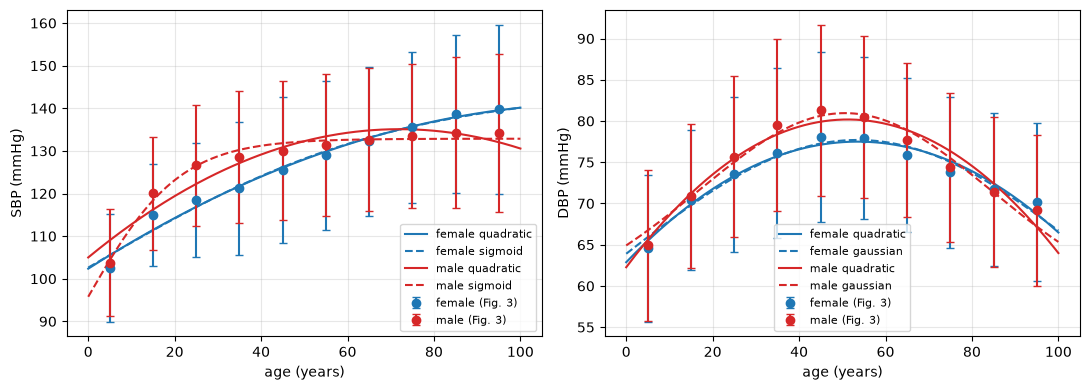

In [ ]:
x_fine = np.linspace(0, 100, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, bp in zip(axes, ["sbp", "dbp"]):
    for sex in SEXES:
        ax.errorbar(age, df[f"{bp}_{sex}"], yerr=df[f"{bp}_{sex}_std"],
                    fmt="o", color=COLORS[sex], capsize=3, label=f"{sex} (Fig. 3)")
        for style, model in zip(["-", "--"], MODELS[bp]):
            ax.plot(x_fine, fits[(sex, bp, model.name)].predict(x_fine), style,
                    color=COLORS[sex], label=f"{sex} {model.name}")
    ax.set_xlabel("age (years)")
    ax.set_ylabel(f"{bp.upper()} (mmHg)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("../figs/fig_all_fits.png", dpi=150)

In [ ]:
rows = []
for (sex, bp, name), fit in fits.items():
    y = df[f"{bp}_{sex}"].values
    resid = y - fit.predict(age)
    n, k = len(y), fit.n_params
    rss = np.sum(resid**2)
    rows.append(dict(
        sex=sex, bp=bp, model=name, k=k,
        MSE=rss / n,
        R2=1 - rss / np.sum((y - y.mean())**2),
        AIC=n * np.log(rss / n) + 2 * k,
        AICc=n * np.log(rss / n) + 2 * k + 2 * k * (k + 1) / (n - k - 1),
        BIC=n * np.log(rss / n) + k * np.log(n),
    ))
metrics = pd.DataFrame(rows).set_index(["sex", "bp", "model"])
metrics.to_csv("outputs/metrics.csv")
print(metrics.round(3).to_string())

print("\nbest model per (sex, bp):")
for crit in ["MSE", "AIC", "AICc", "BIC"]:
    best = metrics[crit].groupby(level=["sex", "bp"]).idxmin().map(lambda t: t[2])
    print(f"{crit:5s}", dict(best))

                      k    MSE     R2     AIC    AICc     BIC
sex    bp  model                                             
female sbp quadratic  3  2.623  0.979  15.641  19.641  16.549
           sigmoid    4  2.833  0.977  18.413  26.413  19.623
       dbp quadratic  3  0.762  0.951   3.278   7.278   4.185
           gaussian   4  0.832  0.947   6.160  14.160   7.370
male   sbp quadratic  3  7.965  0.900  26.751  30.751  27.658
           sigmoid    4  1.459  0.982  11.774  19.774  12.985
       dbp quadratic  3  1.463  0.944   9.807  13.807  10.715
           gaussian   4  1.188  0.955   9.719  17.719  10.929

best model per (sex, bp):
MSE   {('female', 'dbp'): 'quadratic', ('female', 'sbp'): 'quadratic', ('male', 'dbp'): 'gaussian', ('male', 'sbp'): 'sigmoid'}
AIC   {('female', 'dbp'): 'quadratic', ('female', 'sbp'): 'quadratic', ('male', 'dbp'): 'gaussian', ('male', 'sbp'): 'sigmoid'}
AICc  {('female', 'dbp'): 'quadratic', ('female', 'sbp'): 'quadratic', ('male', 'dbp'): 'quadrati

### A1) The Polynomial model
$a$ - age in years
$$SBP(a) = c_1 a^2 + c_2 a + c_3, \qquad DBP(a) = d_1 a^2 + d_2 a + d_3$$
### The sigmoid model for SBP

$$SBP(a) = S_0 + \frac{\Delta S}{1 + e^{-k(a-a_0)}}$$

### The Gaussian model for DBP

$$DBP(a) = D_0 + \Delta D\, e^{-\frac{(a-a_{peak})^2}{2\sigma^2}}$$